In [1]:
from pathlib import Path
import pandas as pd

# Find the project folder
root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

# Get the Phase 1 portfolio return data
file_path = root / "data" / "processed" / "portfolio_returns.csv"

df = pd.read_csv(file_path)

# Check the result
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Shape: (4232, 6)
Columns: ['Date', 'portfolio_return', 'realized_pnl_usd', 'realized_loss_usd', 'wealth_index', 'cumulative_return']


,Date,portfolio_return,realized_pnl_usd,realized_loss_usd,wealth_index,cumulative_return
0,2010-01-05,0.001357,1357.130955,-1357.130955,1.001357,0.001357
1,2010-01-06,-0.000736,-735.656880,735.656880,1.000620,0.000620
2,2010-01-07,0.001992,1991.948855,-1991.948855,1.002614,0.002614
3,2010-01-08,0.005792,5792.439242,-5792.439242,1.008421,0.008421
4,2010-01-11,-0.000453,-453.393153,453.393153,1.007964,0.007964


5% Return Quantile: -1.7357%
1% Return Quantile: -3.1627%


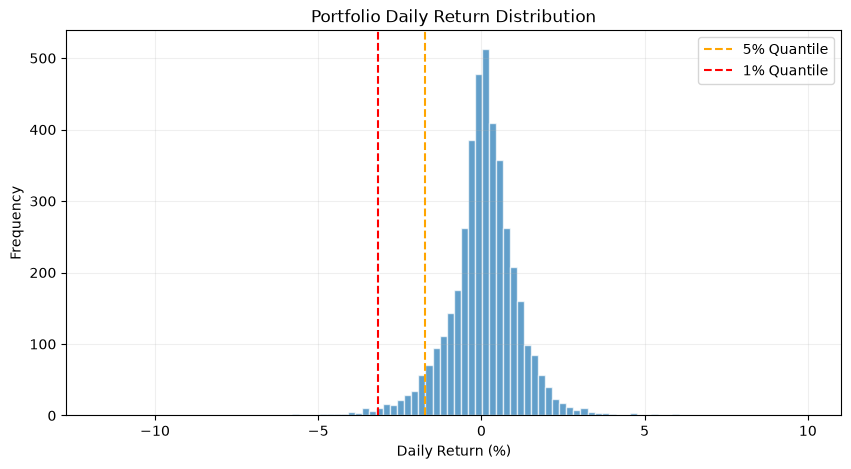

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Extract portfolio daily returns
returns = df["portfolio_return"].dropna()

# Calculate historical quantiles
q_05 = np.quantile(returns, 0.05)
q_01 = np.quantile(returns, 0.01)

print(f"5% Return Quantile: {q_05:.4%}")
print(f"1% Return Quantile: {q_01:.4%}")

# Plot historical return distribution
plt.figure(figsize=(10, 5))

plt.hist(
    returns * 100,
    bins=100,
    alpha=0.7,
    edgecolor="white"
)

plt.axvline(
    q_05 * 100,
    color="orange",
    linestyle="--",
    label="5% Quantile"
)

plt.axvline(
    q_01 * 100,
    color="red",
    linestyle="--",
    label="1% Quantile"
)

plt.title("Portfolio Daily Return Distribution")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [3]:
# Historical Simulation VaR using all available returns
var_95 = -q_05
var_99 = -q_01

print(f"95% Historical VaR: {var_95:.4%}")
print(f"99% Historical VaR: {var_99:.4%}")

95% Historical VaR: 1.7357%
99% Historical VaR: 3.1627%


In [4]:
# Select returns in the worst 5% and 1% tails
tail_95 = returns[returns <= q_05]
tail_99 = returns[returns <= q_01]

# Calculate tail average losses
es_95 = -tail_95.mean()
es_99 = -tail_99.mean()

print(f"95% Historical ES: {es_95:.4%}")
print(f"99% Historical ES: {es_99:.4%}")

print(f"95% Tail Observations: {len(tail_95)}")
print(f"99% Tail Observations: {len(tail_99)}")

95% Historical ES: 2.7112%
99% Historical ES: 4.4866%
95% Tail Observations: 212
99% Tail Observations: 43


In [5]:
print("95% ES >= VaR:", es_95 >= var_95)
print("99% ES >= VaR:", es_99 >= var_99)

95% ES >= VaR: True
99% ES >= VaR: True


500-Day Historical Simulation

In [6]:
# Step 6: First 500-day estimation window

window = 500

first_window = returns.iloc[:window]

# Calculate VaR
var_95_500 = -np.quantile(first_window, 0.05)
var_99_500 = -np.quantile(first_window, 0.01)

# Calculate preliminary ES
es_95_500 = -first_window[
    first_window <= np.quantile(first_window, 0.05)
].mean()

es_99_500 = -first_window[
    first_window <= np.quantile(first_window, 0.01)
].mean()

print(f"95% VaR (500 days): {var_95_500:.4%}")
print(f"99% VaR (500 days): {var_99_500:.4%}")

print(f"95% ES (500 days): {es_95_500:.4%}")
print(f"99% ES (500 days): {es_99_500:.4%}")

print("First observation:", df["Date"].iloc[0])
print("Last estimation observation:", df["Date"].iloc[499])
print("First forecast target:", df["Date"].iloc[500])

95% VaR (500 days): 2.4551%
99% VaR (500 days): 4.0437%
95% ES (500 days): 3.4679%
99% ES (500 days): 5.1578%
First observation: 2010-01-05
Last estimation observation: 2011-12-27
First forecast target: 2011-12-28


In [7]:
def historical_var(returns, confidence_level=0.95):

    alpha = 1 - confidence_level

    var = -np.quantile(
        returns,
        alpha,
        method="linear"
    )

    return float(var)

In [8]:
print(f"95% VaR: {historical_var(first_window, 0.95):.4%}")
print(f"99% VaR: {historical_var(first_window, 0.99):.4%}")

95% VaR: 2.4551%
99% VaR: 4.0437%


In [9]:

def historical_es(returns, confidence_level=0.95):

    returns = np.asarray(returns, dtype=float)

    # Sort returns from worst to best
    sorted_returns = np.sort(returns)

    # Calculate the tail probability
    alpha = 1 - confidence_level

    # Number of observations in the tail
    tail_size = len(sorted_returns) * alpha

    # Full observations and fractional remainder
    k = int(np.floor(tail_size))
    fraction = tail_size - k

    # Sum the worst k returns
    tail_sum = np.sum(sorted_returns[:k])

    # Include fractional weight of the next return
    if fraction > 0:
        tail_sum += fraction * sorted_returns[k]

    # Convert average tail return to a positive loss
    es = -tail_sum / tail_size

    return float(es)


In [10]:
print(f"95% ES: {historical_es(first_window, 0.95):.4%}")
print(f"99% ES: {historical_es(first_window, 0.99):.4%}")

95% ES: 3.4679%
99% ES: 5.1578%


In [11]:
print(
    "95% ES >= VaR:",
    historical_es(first_window, 0.95)
    >= historical_var(first_window, 0.95)
)

print(
    "99% ES >= VaR:",
    historical_es(first_window, 0.99)
    >= historical_var(first_window, 0.99)
)

95% ES >= VaR: True
99% ES >= VaR: True


In [12]:
import sys

# Allow imports from the project root
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.historical_var import historical_var, historical_es

print(f"95% VaR: {historical_var(first_window, 0.95):.4%}")
print(f"99% VaR: {historical_var(first_window, 0.99):.4%}")

print(f"95% ES: {historical_es(first_window, 0.95):.4%}")
print(f"99% ES: {historical_es(first_window, 0.99):.4%}")

95% VaR: 2.4551%
99% VaR: 4.0437%
95% ES: 3.4679%
99% ES: 5.1578%


In [13]:

# Step 13: 500-Day Rolling Historical VaR / ES

window = 500

forecast_results = []

for t in range(window, len(returns)):

    # Use only the previous 500 returns
    historical_window = returns.iloc[t-window:t]

    # Calculate VaR and ES
    var_95 = historical_var(historical_window, 0.95)
    var_99 = historical_var(historical_window, 0.99)

    es_95 = historical_es(historical_window, 0.95)
    es_99 = historical_es(historical_window, 0.99)

    # Store forecast and realized return
    forecast_results.append({
        "Date": df["Date"].iloc[t],
        "actual_return": returns.iloc[t],
        "var_95": var_95,
        "var_99": var_99,
        "es_95": es_95,
        "es_99": es_99
    })

rolling_df = pd.DataFrame(forecast_results)

print("Forecast observations:", len(rolling_df))

display(rolling_df.head())


Forecast observations: 3732


,Date,actual_return,var_95,var_99,es_95,es_99
0,2011-12-28,-0.014352,0.024551,0.040437,0.034679,0.051578
1,2011-12-29,0.010431,0.024551,0.040437,0.034679,0.051578
2,2011-12-30,-0.002924,0.024551,0.040437,0.034679,0.051578
3,2012-01-03,0.019430,0.024551,0.040437,0.034679,0.051578
4,2012-01-04,-0.000290,0.024551,0.040437,0.034679,0.051578


In [14]:
print("Total forecasts:", len(rolling_df))
print("First forecast:", rolling_df["Date"].iloc[0])
print("Last forecast:", rolling_df["Date"].iloc[-1])

print("Missing values:")
print(rolling_df.isna().sum())

Total forecasts: 3732
First forecast: 2011-12-28
Last forecast: 2026-10-30
Missing values:
Date             0
actual_return    0
var_95           0
var_99           0
es_95            0
es_99            0
dtype: int64


In [15]:
# Step 14: Convert actual returns to losses

rolling_df["actual_loss"] = -rolling_df["actual_return"]

# Convert Date to datetime
rolling_df["Date"] = pd.to_datetime(rolling_df["Date"])

# Check the result
display(
    rolling_df[
        ["Date", "actual_return", "actual_loss",
         "var_95", "var_99"]
    ].head()
)

,Date,actual_return,actual_loss,var_95,var_99
0,2011-12-28,-0.014352,0.014352,0.024551,0.040437
1,2011-12-29,0.010431,-0.010431,0.024551,0.040437
2,2011-12-30,-0.002924,0.002924,0.024551,0.040437
3,2012-01-03,0.019430,-0.019430,0.024551,0.040437
4,2012-01-04,-0.000290,0.000290,0.024551,0.040437


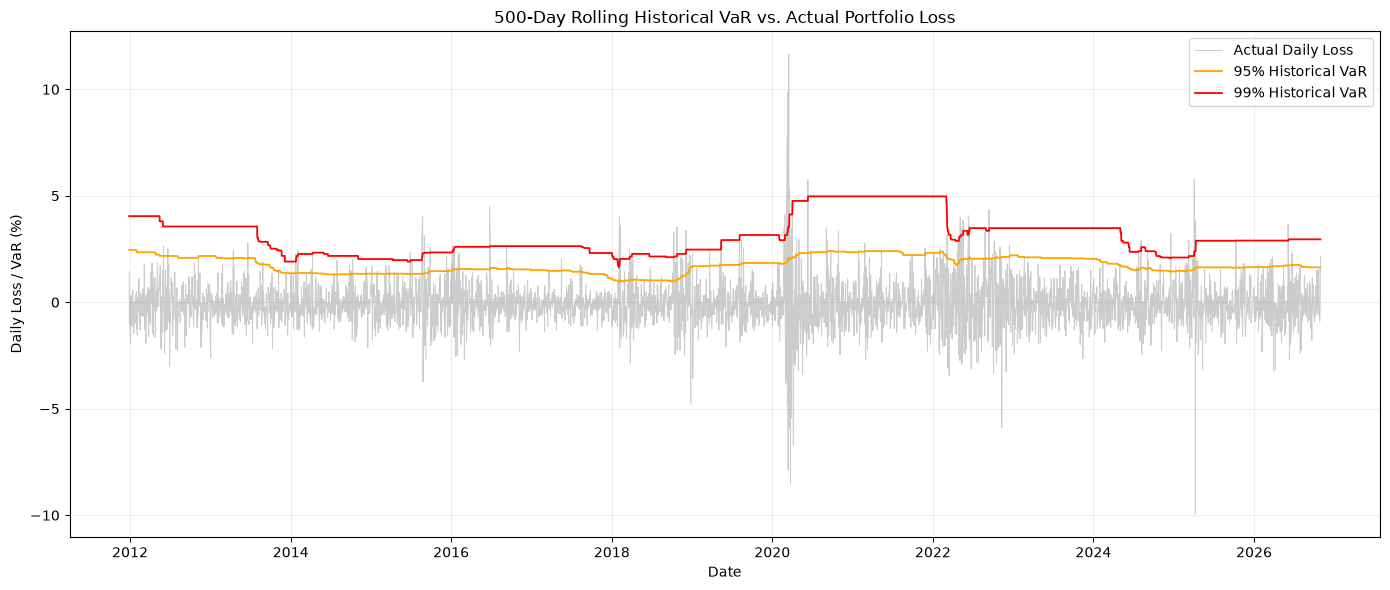

In [16]:
# Step 15: Rolling Historical VaR Visualization

plt.figure(figsize=(14, 6))

# Actual portfolio losses
plt.plot(
    rolling_df["Date"],
    rolling_df["actual_loss"] * 100,
    color="gray",
    alpha=0.4,
    linewidth=0.7,
    label="Actual Daily Loss"
)

# 95% Historical VaR
plt.plot(
    rolling_df["Date"],
    rolling_df["var_95"] * 100,
    color="orange",
    linewidth=1.3,
    label="95% Historical VaR"
)

# 99% Historical VaR
plt.plot(
    rolling_df["Date"],
    rolling_df["var_99"] * 100,
    color="red",
    linewidth=1.3,
    label="99% Historical VaR"
)

plt.title("500-Day Rolling Historical VaR vs. Actual Portfolio Loss")
plt.xlabel("Date")
plt.ylabel("Daily Loss / VaR (%)")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [18]:
# Step 17: Export Historical Simulation Forecasts

from pathlib import Path

# Create output directory
output_dir = root / "results"
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare export data
export_df = rolling_df[
    [
        "Date",
        "actual_return",
        "actual_loss",
        "var_95",
        "var_99",
        "es_95",
        "es_99",
        "exception_95",
        "exception_99"
    ]
].copy()

# Save results
output_path = output_dir / "historical_var_es_forecasts.csv"

export_df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Rows:", len(export_df))

display(export_df.head())

Saved to: /Users/tzuling/Desktop/HW/self project/portfolio-var-es-backtesting/results/historical_var_es_forecasts.csv
Rows: 3732


,Date,actual_return,actual_loss,var_95,var_99,es_95,es_99,exception_95,exception_99
0,2011-12-28,-0.014352,0.014352,0.024551,0.040437,0.034679,0.051578,False,False
1,2011-12-29,0.010431,-0.010431,0.024551,0.040437,0.034679,0.051578,False,False
2,2011-12-30,-0.002924,0.002924,0.024551,0.040437,0.034679,0.051578,False,False
3,2012-01-03,0.019430,-0.019430,0.024551,0.040437,0.034679,0.051578,False,False
4,2012-01-04,-0.000290,0.000290,0.024551,0.040437,0.034679,0.051578,False,False


In [17]:
# Step 16: Identify VaR exceptions

rolling_df["exception_95"] = (
    rolling_df["actual_loss"] > rolling_df["var_95"]
)

rolling_df["exception_99"] = (
    rolling_df["actual_loss"] > rolling_df["var_99"]
)

# Count exceptions
n_95 = rolling_df["exception_95"].sum()
n_99 = rolling_df["exception_99"].sum()

# Calculate observed exception rates
rate_95 = rolling_df["exception_95"].mean()
rate_99 = rolling_df["exception_99"].mean()

print(f"95% VaR Exceptions: {n_95}")
print(f"95% Exception Rate: {rate_95:.2%}")

print(f"99% VaR Exceptions: {n_99}")
print(f"99% Exception Rate: {rate_99:.2%}")

95% VaR Exceptions: 176
95% Exception Rate: 4.72%
99% VaR Exceptions: 50
99% Exception Rate: 1.34%


In [19]:
# Step 17: Export Historical Simulation Forecasts

from pathlib import Path

# Create output directory
output_dir = root / "results"
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare export data
export_df = rolling_df[
    [
        "Date",
        "actual_return",
        "actual_loss",
        "var_95",
        "var_99",
        "es_95",
        "es_99",
        "exception_95",
        "exception_99"
    ]
].copy()

# Save results
output_path = output_dir / "historical_var_es_forecasts.csv"

export_df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Rows:", len(export_df))

display(export_df.head())

Saved to: /Users/tzuling/Desktop/HW/self project/portfolio-var-es-backtesting/results/historical_var_es_forecasts.csv
Rows: 3732


,Date,actual_return,actual_loss,var_95,var_99,es_95,es_99,exception_95,exception_99
0,2011-12-28,-0.014352,0.014352,0.024551,0.040437,0.034679,0.051578,False,False
1,2011-12-29,0.010431,-0.010431,0.024551,0.040437,0.034679,0.051578,False,False
2,2011-12-30,-0.002924,0.002924,0.024551,0.040437,0.034679,0.051578,False,False
3,2012-01-03,0.019430,-0.019430,0.024551,0.040437,0.034679,0.051578,False,False
4,2012-01-04,-0.000290,0.000290,0.024551,0.040437,0.034679,0.051578,False,False


In [20]:
# Step 18: Final rolling forecast validation

assert len(rolling_df) == 3732

assert rolling_df["Date"].is_unique

assert rolling_df[
    ["var_95", "var_99", "es_95", "es_99"]
].notna().all().all()

assert (rolling_df["var_99"] >= rolling_df["var_95"]).all()

assert (rolling_df["es_95"] >= rolling_df["var_95"]).all()

assert (rolling_df["es_99"] >= rolling_df["var_99"]).all()

assert (
    rolling_df["actual_loss"]
    == -rolling_df["actual_return"]
).all()

print("All rolling forecast checks passed!")

All rolling forecast checks passed!
